<a href="https://colab.research.google.com/github/Wasayyyyyy/CV-Tasks/blob/main/LAB%2010%20-%20Assignment%203/A3_Regression_Comparison_FA23_BAI_043.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Implementation of Machine Learning Regression Algorithms

Six regressors (Linear Regression, Decision Tree, Random Forest, Neural Network, XGBoost, KNN) trained on the **Diabetes** dataset with the same features, target and 80:20 split, tuned by 5-fold CV on the training set and evaluated with MAE, MSE, RMSE and R².

Run all cells top to bottom (about 1–3 minutes).

## Setup: install required libraries

Run once. Restart the kernel if `xgboost` was just installed.

In [1]:
%pip install -q scikit-learn xgboost pandas matplotlib

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42

import xgboost
from xgboost import XGBRegressor
XGB_SOURCE = f"xgboost library v{xgboost.__version__}"
def make_xgb():
    return XGBRegressor(objective="reg:squarederror", tree_method="exact",
                        random_state=SEED, n_jobs=1)

## 1. Load data

In [3]:
data = load_diabetes(scaled=False, as_frame=True)
df = data.frame.rename(columns={"s1": "tc", "s2": "ldl", "s3": "hdl",
                                "s4": "tch", "s5": "ltg", "s6": "glu"})
print("Shape:", df.shape)
print("Missing values per column:\n", df.isna().sum().to_string())
print("Duplicate rows:", df.duplicated().sum())

Shape: (442, 11)
Missing values per column:
 age       0
sex       0
bmi       0
bp        0
tc        0
ldl       0
hdl       0
tch       0
ltg       0
glu       0
target    0
Duplicate rows: 0


## 2. Preprocessing

In [4]:
df["sex"] = (df["sex"] == 2).astype(int)          # encode binary category as 0/1
FEATURES = [c for c in df.columns if c != "target"]
X, y = df[FEATURES], df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

# Scale-sensitive models get a StandardScaler inside a Pipeline, so the scaler
# is fitted on training folds only (no leakage into validation/test data).
def scaled(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

Train: (353, 10)  Test: (89, 10)


## 3. Models + hyper-parameter grids (tuned by 5-fold CV on training data)

In [5]:
models = {
    "Linear Regression": (scaled(LinearRegression()), {}),
    "Decision Tree": (DecisionTreeRegressor(random_state=SEED), {
        "max_depth": [2, 3, 4, 5, 6, 8, None],
        "min_samples_leaf": [1, 5, 10, 20, 30]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), {
        "max_depth": [None, 4, 8],
        "min_samples_leaf": [1, 3, 5, 10],
        "max_features": [1.0, 0.5, "sqrt"]}),
    "Neural Network": (scaled(MLPRegressor(solver="lbfgs", max_iter=5000, random_state=SEED)), {
        "model__hidden_layer_sizes": [(8,), (16,), (32, 16)],
        "model__alpha": [0.1, 1.0, 10.0, 30.0]}),
    "XGBoost": (make_xgb(), {
        "n_estimators": [100, 300],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
        "reg_lambda": [1.0, 10.0]}),
    "KNN": (scaled(KNeighborsRegressor()), {
        "model__n_neighbors": list(range(1, 31)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]}),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results, predictions, best_params, cv_scores = [], {}, {}, {}

for name, (est, grid) in models.items():
    search = GridSearchCV(est, grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    y_pred = best.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred),
    })
    predictions[name] = y_pred
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    # Cross-validated R2 of the tuned configuration on the training set:
    # a second, less noisy view than a single 89-row test set.
    cv_r2 = cross_val_score(best, X_train, y_train, cv=cv, scoring="r2")
    cv_scores[name] = (cv_r2.mean(), cv_r2.std())
    print(f"{name:18s} done | best params: {best_params[name]}")

res = pd.DataFrame(results).set_index("Model")
res["CV R2 (mean)"] = [cv_scores[m][0] for m in res.index]
res["CV R2 (std)"] = [cv_scores[m][1] for m in res.index]
res = res.sort_values("RMSE")
print("\nXGBoost source:", XGB_SOURCE)
print("\n=== Test-set performance (sorted by RMSE) ===")
print(res.round(4).to_string())

# Baseline for context: always predict the training mean
base = np.full_like(y_test, y_train.mean(), dtype=float)
print(f"\nMean-predictor baseline: MAE={mean_absolute_error(y_test, base):.2f} "
      f"RMSE={np.sqrt(mean_squared_error(y_test, base)):.2f} R2={r2_score(y_test, base):.4f}")

# Linear-regression coefficients (standardised) for interpretation
lr = models["Linear Regression"][0].fit(X_train, y_train)
coefs = pd.Series(lr.named_steps["model"].coef_, index=FEATURES).sort_values(key=abs, ascending=False)
print("\nStandardised LR coefficients:\n", coefs.round(2).to_string())

Linear Regression  done | best params: {}
Decision Tree      done | best params: {'max_depth': 2, 'min_samples_leaf': 1}
Random Forest      done | best params: {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 5}
Neural Network     done | best params: {'alpha': 30.0, 'hidden_layer_sizes': (8,)}
XGBoost            done | best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'reg_lambda': 10.0}
KNN                done | best params: {'n_neighbors': 22, 'p': 2, 'weights': 'distance'}

XGBoost source: xgboost library v3.4.1

=== Test-set performance (sorted by RMSE) ===
                       MAE        MSE     RMSE      R2  CV R2 (mean)  CV R2 (std)
Model                                                                            
XGBoost            42.4765  2760.6995  52.5424  0.4789        0.4353       0.0399
Random Forest      42.7232  2772.0721  52.6505  0.4768        0.4482       0.0355
Neural Network     41.7363  2876.3408  53.6315  0.4571        0.3886    

## 4. Visualisations

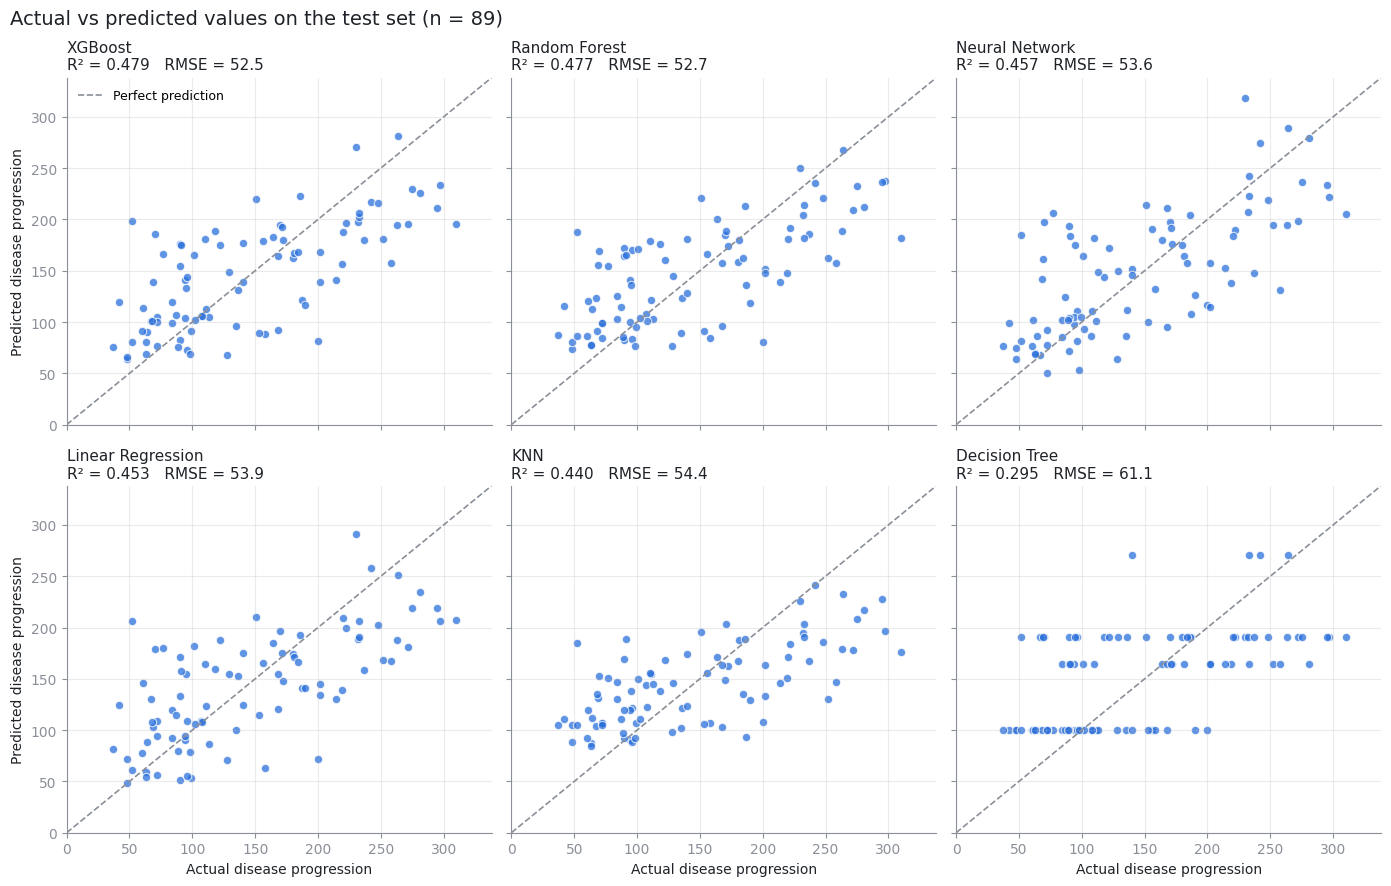

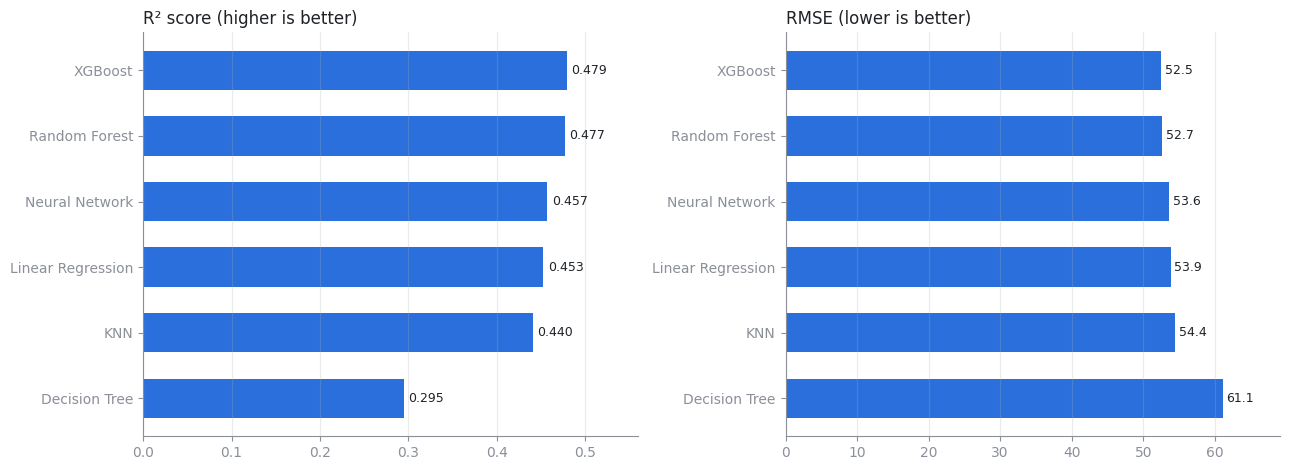

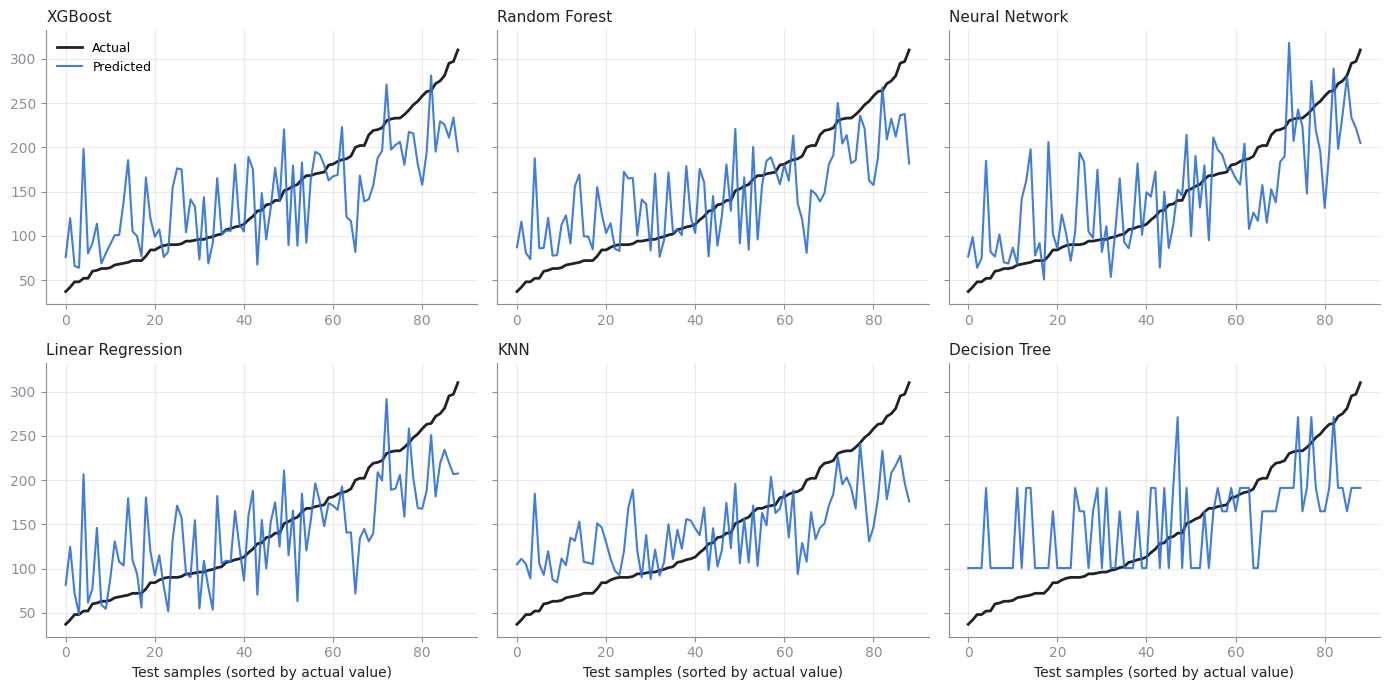


Saved: results_table.csv, results.json, fig_*.png


In [6]:
INK, MUTED, MARK = "#1f2328", "#8a8f98", "#2a6fdb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})

order = list(res.index)
lo, hi = 0, max(y_test.max(), max(p.max() for p in predictions.values())) + 20

# (a) Actual vs predicted -- one panel per model
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), order):
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1.2, ls="--", label="Perfect prediction")
    ax.scatter(y_test, predictions[name], s=36, color=MARK, alpha=0.75,
               edgecolor="white", linewidth=0.8)
    r = res.loc[name]
    ax.set_title(f"{name}\nR² = {r.R2:.3f}   RMSE = {r.RMSE:.1f}", fontsize=11, color=INK, loc="left")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.grid(alpha=0.25)
for ax in axes[1]: ax.set_xlabel("Actual disease progression")
for ax in axes[:, 0]: ax.set_ylabel("Predicted disease progression")
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Actual vs predicted values on the test set (n = 89)", fontsize=14, color=INK, x=0.01, ha="left")
fig.tight_layout(); fig.savefig("fig_actual_vs_predicted.png", dpi=160); plt.show()

# (b) R2 and RMSE comparison
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.barh(order[::-1], res["R2"][::-1], color=MARK, height=0.6)
for i, v in enumerate(res["R2"][::-1]): a1.text(v + 0.005, i, f"{v:.3f}", va="center", color=INK, fontsize=9)
a1.set_title("R² score (higher is better)", loc="left", color=INK); a1.set_xlim(0, res["R2"].max() + 0.08)
a2.barh(order[::-1], res["RMSE"][::-1], color=MARK, height=0.6)
for i, v in enumerate(res["RMSE"][::-1]): a2.text(v + 0.5, i, f"{v:.1f}", va="center", color=INK, fontsize=9)
a2.set_title("RMSE (lower is better)", loc="left", color=INK); a2.set_xlim(0, res["RMSE"].max() + 8)
for a in (a1, a2): a.grid(axis="x", alpha=0.25)
fig.tight_layout(); fig.savefig("fig_metric_comparison.png", dpi=160); plt.show()

# (c) Actual vs predicted along the test samples (sorted by actual value)
idx = np.argsort(y_test.values)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, name in zip(axes.ravel(), order):
    ax.plot(y_test.values[idx], color=INK, lw=2, label="Actual")
    ax.plot(predictions[name][idx], color=MARK, lw=1.5, alpha=0.9, label="Predicted")
    ax.set_title(name, loc="left", color=INK, fontsize=11); ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False, fontsize=9)
for ax in axes[1]: ax.set_xlabel("Test samples (sorted by actual value)")
fig.tight_layout(); fig.savefig("fig_actual_vs_predicted_lines.png", dpi=160); plt.show()

# Save everything the report needs
res.round(4).to_csv("results_table.csv")
json.dump({"xgb_source": XGB_SOURCE, "best_params": {k: {kk: (str(vv) if not isinstance(vv, (int, float)) else vv)
           for kk, vv in v.items()} for k, v in best_params.items()},
           "baseline": {"MAE": mean_absolute_error(y_test, base),
                        "RMSE": float(np.sqrt(mean_squared_error(y_test, base))),
                        "R2": r2_score(y_test, base)},
           "coefs": coefs.round(3).to_dict(),
           "pred": {k: v.round(2).tolist() for k, v in predictions.items()},
           "actual": y_test.tolist()},
          open("results.json", "w"), indent=1)
print("\nSaved: results_table.csv, results.json, fig_*.png")

## 5. Is the winner's margin real? Paired bootstrap of test-set RMSE

In [7]:
rng = np.random.default_rng(SEED)
best_name = res.index[0]
yt = y_test.values
boot = {m: [] for m in res.index if m != best_name}
for _ in range(5000):
    i = rng.integers(0, len(yt), len(yt))
    rb = np.sqrt(np.mean((yt[i] - predictions[best_name][i]) ** 2))
    for m in boot:
        boot[m].append(np.sqrt(np.mean((yt[i] - predictions[m][i]) ** 2)) - rb)
print(f"\nPaired bootstrap: RMSE(model) - RMSE({best_name}), 95% CI and P(model worse)")
for m, d in boot.items():
    d = np.array(d)
    print(f"  {m:18s} diff={d.mean():6.2f}  CI=[{np.percentile(d,2.5):6.2f}, {np.percentile(d,97.5):6.2f}]  P(worse)={np.mean(d>0):.2f}")


Paired bootstrap: RMSE(model) - RMSE(XGBoost), 95% CI and P(model worse)
  Random Forest      diff=  0.10  CI=[ -2.24,   2.57]  P(worse)=0.53
  Neural Network     diff=  1.07  CI=[ -3.49,   5.54]  P(worse)=0.68
  Linear Regression  diff=  1.30  CI=[ -2.03,   4.64]  P(worse)=0.79
  KNN                diff=  1.94  CI=[ -2.34,   6.44]  P(worse)=0.80
  Decision Tree      diff=  8.54  CI=[  2.29,  14.88]  P(worse)=1.00


## 6. Discussion and Conclusion

| Algorithm | Strength | Limitation |
|---|---|---|
| Linear Regression | Simple, fast, interpretable | Assumes a linear relationship |
| Decision Tree | Easy-to-read rules | Overfits; only 4 output values here |
| Random Forest | Stable; resists overfitting | Slower, less interpretable |
| Neural Network | Learns complex patterns | Needs lots of data and tuning |
| XGBoost | Accurate, built-in regularisation | Many hyper-parameters |
| KNN | No training, intuitive | Needs scaling; sensitive to k |

**Best model: XGBoost.** It has the lowest MSE (2760.70) and RMSE (52.54) and the highest R² (0.479). Boosting corrects errors tree by tree, and its regularisation prevents overfitting on this small dataset.

The top five models are within 1.9 RMSE of each other, so the lead is small. Only the Decision Tree is clearly worse.

## Appendix: verification of the handwritten calculations

Recomputes every number used in Part A of the report on the 6-row training sample and 2 test rows.

In [8]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

# 6 training rows (dataset rows 0-5) and 2 test rows (rows 6 and 8): features BMI, BP
Xtr = np.array([[32.1, 101], [21.6, 87], [30.5, 93], [25.3, 84], [23.0, 101], [22.6, 89]])
ytr = np.array([151, 75, 141, 206, 135, 97], float)
Xte = np.array([[22.0, 90], [32.1, 83]])
yte = np.array([138, 110], float)
P = {}

print("=== 1. LINEAR REGRESSION ===")
x = Xtr[:, 0]; xm, ym = x.mean(), ytr.mean()
Sxy = np.sum((x - xm) * (ytr - ym)); Sxx = np.sum((x - xm) ** 2)
b1 = Sxy / Sxx; b0 = ym - b1 * xm
print(f"xbar={xm:.4f} ybar={ym:.4f}")
print("dx", (x - xm).round(4), "dy", (ytr - ym).round(4))
print("dx*dy", ((x - xm) * (ytr - ym)).round(4), "dx^2", ((x - xm) ** 2).round(4))
print(f"Sxy={Sxy:.4f} Sxx={Sxx:.4f} b1={b1:.4f} b0={b0:.4f}")
print("simple LR test preds", (b0 + b1 * Xte[:, 0]).round(2))
A = np.c_[np.ones(6), Xtr]
XtX = A.T @ A; Xty = A.T @ ytr; beta = np.linalg.solve(XtX, Xty)
print("XtX\n", XtX, "\nXty", Xty, "\nbeta", beta.round(4))
P["LR"] = np.c_[np.ones(2), Xte] @ beta
print("multiple LR test preds", P["LR"].round(2))
print("train preds", (A @ beta).round(2))

print("\n=== 2. DECISION TREE (stump, SSE criterion) ===")
def stump_table(X, y, feats=(0, 1), show=True):
    best = None
    for j in feats:
        xs = np.unique(X[:, j])
        for t in (xs[:-1] + xs[1:]) / 2:
            L, R = y[X[:, j] <= t], y[X[:, j] > t]
            sse = ((L - L.mean()) ** 2).sum() + ((R - R.mean()) ** 2).sum()
            if show:
                print(f" f{j} t={t:6.2f} L={L.tolist()} meanL={L.mean():7.2f} R={R.tolist()} meanR={R.mean():7.2f} SSE={sse:9.2f}")
            if best is None or sse < best[0] - 1e-9:
                best = (sse, j, t, L.mean(), R.mean())
    return best
sst = ((ytr - ym) ** 2).sum(); print(f"root SSE={sst:.2f}  root MSE={sst/6:.2f}")
best = stump_table(Xtr, ytr)
print("best", best)
_, j, t, mL, mR = best
P["DT"] = np.where(Xte[:, j] <= t, mL, mR); print("DT test preds", P["DT"])

print("\n=== 3. RANDOM FOREST (3 stumps, bootstrap + 1 random feature) ===")
boots = [[0, 1, 1, 3, 4, 5], [0, 2, 2, 3, 5, 5], [1, 2, 3, 4, 4, 5]]
featsel = [0, 1, 0]
rf_preds = []
for b, f in zip(boots, featsel):
    Xb, yb = Xtr[b], ytr[b]
    print(f" bootstrap rows(1-based)={[i+1 for i in b]} y={yb.tolist()} feature={'BMI' if f==0 else 'BP'}")
    bb = stump_table(Xb, yb, feats=(f,))
    print("  best", bb)
    _, jj, tt, l, r = bb
    pr = np.where(Xte[:, jj] <= tt, l, r); rf_preds.append(pr); print("  tree preds", pr.round(2))
P["RF"] = np.mean(rf_preds, axis=0); print("RF preds", P["RF"].round(2))

print("\n=== 4. NEURAL NETWORK 2-2-1, ReLU hidden, linear out ===")
mu, sd = Xtr.mean(0), Xtr.std(0); ymu, ysd = ytr.mean(), ytr.std()
print("feature mean", mu.round(4), "std", sd.round(4), "| y mean", round(ymu, 4), "y std", round(ysd, 4))
Ztr = (Xtr - mu) / sd; Zte = (Xte - mu) / sd; ztr = (ytr - ymu) / ysd
print("Z train\n", Ztr.round(4), "\nz y", ztr.round(4))
W1 = np.array([[0.5, -0.3], [0.2, 0.4]])  # rows = hidden neuron, cols = input (bmi, bp)
b1n = np.array([0.1, 0.0]); W2 = np.array([0.6, -0.4]); b2n = 0.05; lr = 0.1
def forward(z):
    a1 = W1 @ z + b1n; h = np.maximum(0, a1); out = W2 @ h + b2n
    return a1, h, out
z0, t0 = Ztr[0], ztr[0]
a1, h, out = forward(z0)
print("sample1 z", z0.round(4), "target", round(t0, 4))
print("a1", a1.round(4), "h", h.round(4), "out", round(out, 4), "loss=0.5(out-t)^2", round(0.5*(out-t0)**2, 4))
d_out = out - t0
gW2 = d_out * h; gb2 = d_out
d_h = d_out * W2 * (a1 > 0)
gW1 = np.outer(d_h, z0); gb1 = d_h
print("d_out", round(d_out, 4), "gW2", gW2.round(4), "gb2", round(gb2, 4))
print("d_h", d_h.round(4), "gW1\n", gW1.round(4), "gb1", gb1.round(4))
W2 = W2 - lr * gW2; b2n = b2n - lr * gb2; W1 = W1 - lr * gW1; b1n = b1n - lr * gb1
print("new W2", W2.round(4), "b2", round(b2n, 4), "\nnew W1\n", W1.round(4), "b1", b1n.round(4))
a1n, hn, outn = forward(z0); print("re-forward out", round(outn, 4), "new loss", round(0.5*(outn-t0)**2, 4))
nn_te = []
for z in Zte:
    a, hh, o = forward(z); nn_te.append(o); print(" test z", z.round(4), "a1", a.round(4), "h", hh.round(4), "out", round(o, 4), "-> y", round(o*ysd+ymu, 2))
P["NN"] = np.array(nn_te) * ysd + ymu

print("\n=== 5. XGBOOST (lambda=1, gamma=0, eta=0.3, depth 1, 2 rounds) ===")
lam, eta = 1.0, 0.3
pred = np.full(6, ytr.mean()); trees = []
for rnd in range(2):
    r = ytr - pred  # residual = -g
    print(f" round {rnd+1}: base preds {pred.round(2)} residuals {r.round(2)}")
    sim = lambda rr: rr.sum() ** 2 / (len(rr) + lam)
    root = sim(r); print(f"  root similarity={root:.2f} (sum r={r.sum():.2f})")
    best = None
    for j in (0, 1):
        xs = np.unique(Xtr[:, j])
        for t in (xs[:-1] + xs[1:]) / 2:
            L, R = r[Xtr[:, j] <= t], r[Xtr[:, j] > t]
            g = sim(L) + sim(R) - root
            print(f"   f{j} t={t:6.2f} sumL={L.sum():8.2f} nL={len(L)} simL={sim(L):9.2f} sumR={R.sum():8.2f} nR={len(R)} simR={sim(R):9.2f} gain={g:9.2f}")
            if best is None or g > best[0] + 1e-9: best = (g, j, t)
    g, j, t = best
    L, R = r[Xtr[:, j] <= t], r[Xtr[:, j] > t]
    wL, wR = L.sum() / (len(L) + lam), R.sum() / (len(R) + lam)
    print(f"  best f{j} t={t} gain={g:.2f} leaf L={wL:.4f} R={wR:.4f}")
    trees.append((j, t, wL, wR))
    pred = pred + eta * np.where(Xtr[:, j] <= t, wL, wR)
    print(f"  updated preds {pred.round(2)} | train MSE {np.mean((ytr-pred)**2):.2f}")
pt = np.full(2, ytr.mean())
for j, t, wL, wR in trees: pt = pt + eta * np.where(Xte[:, j] <= t, wL, wR)
P["XGB"] = pt; print("XGB test preds", pt.round(2))

print("\n=== 6. KNN (k=3, Euclidean on standardised features) ===")
knn = []
for z, xr in zip(Zte, Xte):
    d = np.sqrt(((Ztr - z) ** 2).sum(1)); o = np.argsort(d)
    print(" test", xr, "z", z.round(4)); print("  distances", d.round(4), "nearest(1-based)", (o[:3] + 1).tolist(), "y", ytr[o[:3]])
    knn.append(ytr[o[:3]].mean())
P["KNN"] = np.array(knn); print("KNN preds", P["KNN"].round(2))

print("\n=== HAND METRICS on the 2 test rows (actual 138, 110) ===")
for k, p in P.items():
    e = yte - p; mae = np.abs(e).mean(); mse = (e ** 2).mean()
    r2 = 1 - (e ** 2).sum() / ((yte - yte.mean()) ** 2).sum()
    print(f" {k:4s} preds={p.round(2)} err={e.round(2)} MAE={mae:.2f} MSE={mse:.2f} RMSE={np.sqrt(mse):.2f} R2={r2:.3f}")

=== 1. LINEAR REGRESSION ===
xbar=25.8500 ybar=134.1667
dx [ 6.25 -4.25  4.65 -0.55 -2.85 -3.25] dy [ 16.8333 -59.1667   6.8333  71.8333   0.8333 -37.1667]
dx*dy [105.2083 251.4583  31.775  -39.5083  -2.375  120.7917] dx^2 [39.0625 18.0625 21.6225  0.3025  8.1225 10.5625]
Sxy=467.3500 Sxx=97.7350 b1=4.7818 b0=10.5569
simple LR test preds [115.76 164.05]
XtX
 [[    6.     155.1    555.  ]
 [  155.1   4107.07 14417.4 ]
 [  555.   14417.4  51597.  ]] 
Xty [  805.  21276.6 74461. ] 
beta [130.73     5.9587  -1.6281]
multiple LR test preds [115.3  186.88]
train preds [157.57 117.8  161.06 144.73 103.35 120.5 ]

=== 2. DECISION TREE (stump, SSE criterion) ===
root SSE=10372.83  root MSE=1728.81
 f0 t= 22.10 L=[75.0] meanL=  75.00 R=[151.0, 141.0, 206.0, 135.0, 97.0] meanR= 146.00 SSE=  6172.00
 f0 t= 22.80 L=[75.0, 97.0] meanL=  86.00 R=[151.0, 141.0, 206.0, 135.0] meanR= 158.25 SSE=  3412.75
 f0 t= 24.15 L=[75.0, 135.0, 97.0] meanL= 102.33 R=[151.0, 141.0, 206.0] meanR= 166.00 SSE=  4292.67